# 결정 트리(Decision Tree)

* 분류와 회귀에 사용되는 지도 학습 방법
* 데이터 특성으로 부터 추론된 결정 규칙을 통해 값을 예측
* **if-then-else** 결정 규칙을 통해 데이터 학습
* 트리의 깊이가 깊을 수록 복잡한 모델(과대 적합)
* 결정 트리 장점
  * 이해와 해석이 쉽다
  * 시각화가 용이하다
  * 많은 데이터 전처리가 필요하지 않다
  * 수치형과 범주형 데이터 모두를 다룰 수 있다
  * ...

In [1]:
import numpy as np
import graphviz
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_validate

In [2]:
iris = load_iris()
dtMD = tree.DecisionTreeClassifier()
dtMD.fit(iris.data, iris.target)

DecisionTreeClassifier()

In [3]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = dtMD.predict(test_ex)
print(pred, iris['target_names'][pred])

[1] ['versicolor']


In [4]:
dt = tree.export_text(decision_tree=dtMD,
                      feature_names=iris.feature_names)
print(dt)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- sepal length (cm) <= 6.95
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- sepal length (cm) >  6.95
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.10
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.10
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



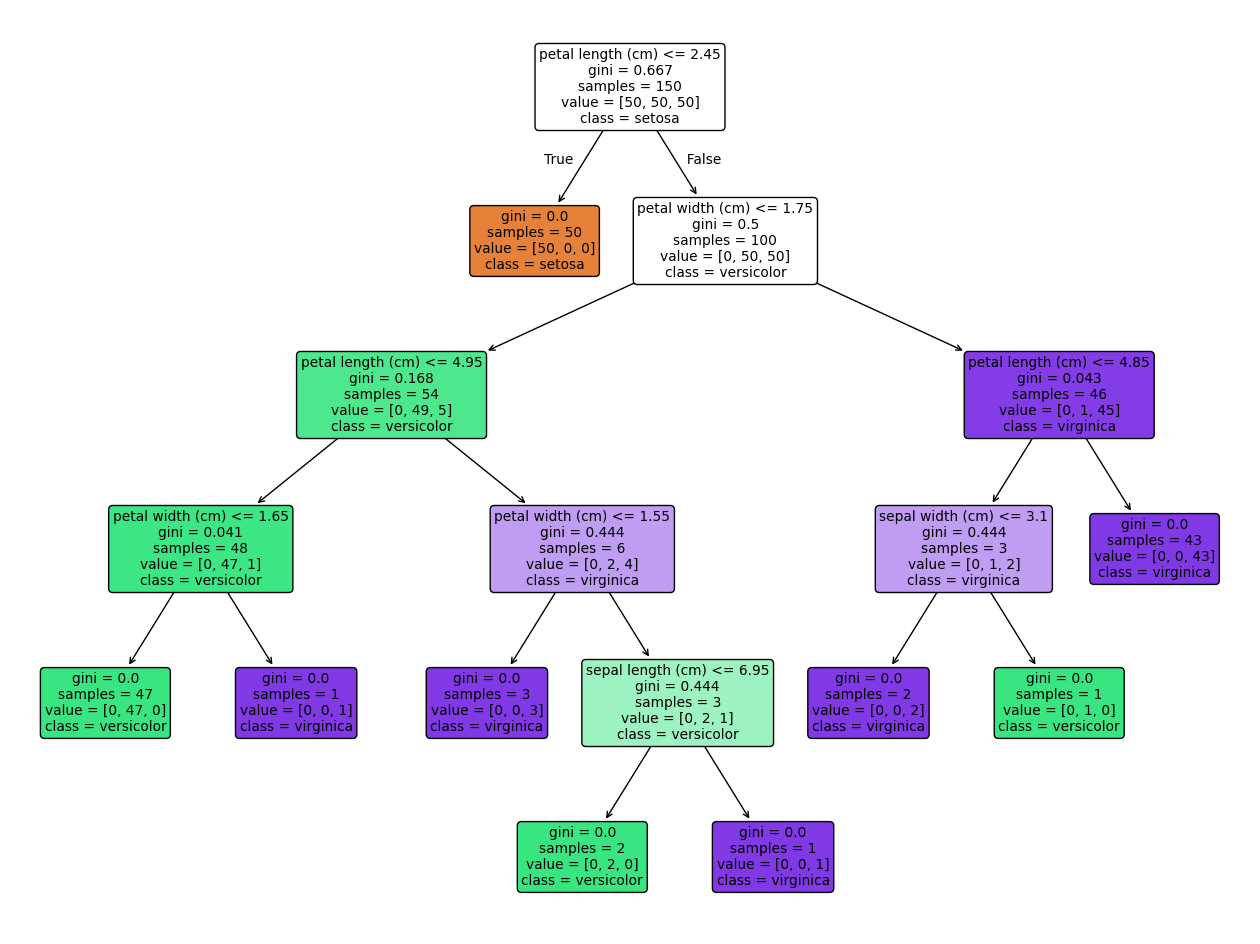

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))
tree.plot_tree(dtMD, filled=True, rounded=True,
               feature_names=iris.feature_names, class_names=iris.target_names) ;

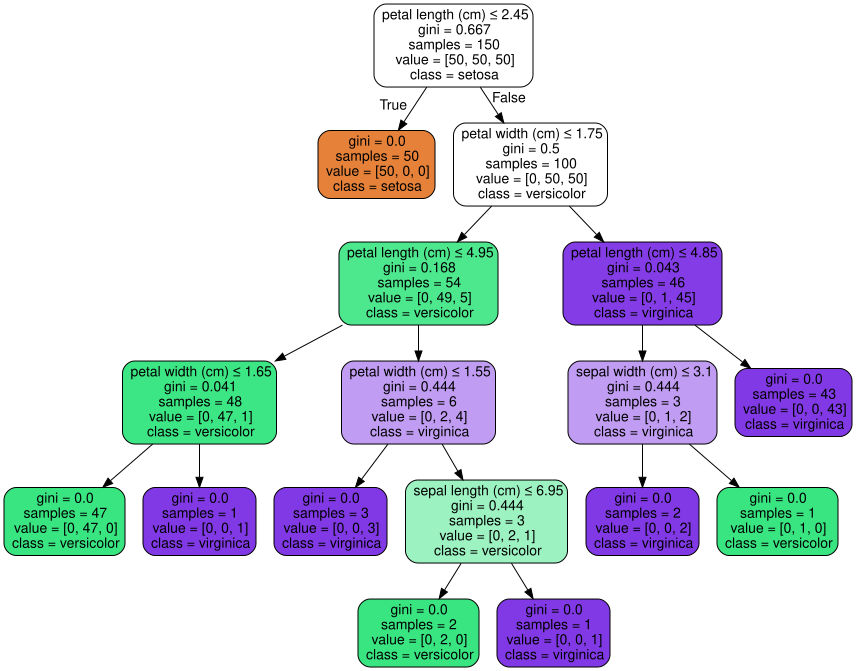

In [7]:
gdt = tree.export_graphviz(decision_tree=dtMD,
                        feature_names=iris.feature_names,
                        class_names=iris.target_names,
                        filled=True, rounded=True,
                        special_characters=True)
graph = graphviz.Source(gdt)
graph

In [8]:
graph.render("dTreeImage", format='png')

'dTreeImage.png'

## Gini, Entropy Index 계산

In [9]:
import numpy as np

def log2(x):
    return np.log2(x)

def gini(*x):
    gi = 1
    for p in x:
        gi -= p**2
    return round(gi, 3)

def entrp(*x):
    ei = 0
    for p in x:
        ei += p*log2(p+1e-7)
    return round(-ei, 3)

print("Gini:", gini(1/2, 1/2))
print("Gini:", gini(4/7, 3/7))
print("Gini:", gini(11/14, 3/14))
print("Gini:", gini(8/9, 1/9))
print("Gini:", gini(9/9, 0/9))
print()
print("Entropy:", entrp(1/2, 1/2))
print("Entropy:", entrp(4/7, 3/7))
print("Entropy:", entrp(11/14, 3/14))
print("Entropy:", entrp(8/9, 1/9))
print("Entropy:", entrp(9/9, 0/9))

Gini: 0.5
Gini: 0.49
Gini: 0.337
Gini: 0.198
Gini: 0.0

Entropy: 1.0
Entropy: 0.985
Entropy: 0.75
Entropy: 0.503
Entropy: -0.0


###전체 23개
 - o: 12개
 - x: 11개

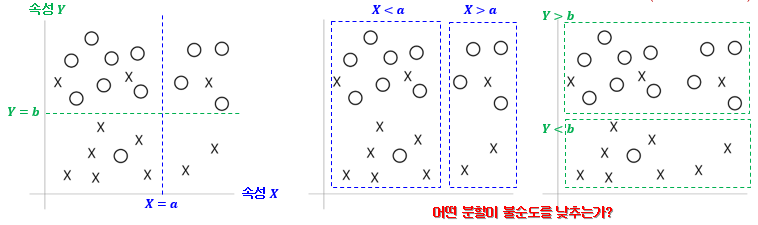

In [ ]:
#초기 상태
print("Gini:", gini(12/23, 11/23))
print("Entropy:", entrp(12/23, 11/23))

Gini: 0.499
Entropy: 0.999


In [10]:
# X=a 기준
print("X<a인 부분")
print("Gini:", gini(8/16, 8/16))
print("Entropy:", entrp(8/16, 8/16))
print("\nX>a인 부분")
print("Gini:", gini(4/7, 3/7))
print("Entropy:", entrp(4/7, 3/7))
print("\nX=a 기준")
print("총 Gini:", gini(8/16, 8/16)+gini(4/7, 3/7))
print("총 Entropy:", entrp(8/16, 8/16)+entrp(4/7, 3/7))

X<a인 부분
Gini: 0.5
Entropy: 1.0

X>a인 부분
Gini: 0.49
Entropy: 0.985

X=a 기준
총 Gini: 0.99
총 Entropy: 1.9849999999999999


In [11]:
# Y=b 기준
print("Y>b인 부분")
print("Gini:", gini(11/14, 3/14))
print("Entropy:", entrp(11/14, 3/14))
print("\nY<b인 부분")
print("Gini:", gini(1/9, 8/9))
print("Entropy:", entrp(1/9, 8/9))
print("\nY=b 기준")
print("총 Gini:", gini(11/14, 3/14)+gini(1/9, 8/9))
print("총 Entropy:", entrp(11/14, 3/14)+entrp(1/9, 8/9))

Y>b인 부분
Gini: 0.337
Entropy: 0.75

Y<b인 부분
Gini: 0.198
Entropy: 0.503

Y=b 기준
총 Gini: 0.535
총 Entropy: 1.2530000000000001
